# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Zhang 2019's follicular-lymphoma malignant manifold is a **single continuous body** (Gate 1
GO, 01). We fit a **principal curve** (ElPiGraph, non-branching by construction) on the *joint*
Harmony embedding — **not** a re-embedding (re-embedding an elongated compartment fabricates
folds, the Kürten §4 / Chen attempt-6 failure). We score the three embryonic modules against
the shared **union** control pool, graph-smooth them for geography, root the curve at the
developmental-origin tip, and render the **actual curve edges** on the manifold to certify it is
fold-free (binding directive).

**Scope decision (derived, and deliberately *not* the -4 attempt's move).** The prior -4 run
excised a 196-cell 95%-cycling lobe to turn whole-manifold Gast/pSom r=−0.16 into +0.33 — a
circular re-scope that manufactured the embryonic pattern and was still judged a failure. Here we
test scope robustness **once, transparently**: we report module correlations on the whole
manifold, on non-cycling cells only, and per patient. Because the embryonic signal is absent
under *every* scope (03), the whole malignant manifold is the honest object and no scoping is
applied. We also report each module's correlation with cell cycle, so the reader can see the
proliferation pocket does not drive the developmental read. Deliverable: `manifold.h5ad`,
`manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
All cells keep their *joint embedding coordinates* — no re-embedding. The three signatures
(Gastrulation / Somitogenesis / Neural-crest) are scored against the shared **union** control
pool and graph-smoothed (kNN-connectivity averaging) so geography can be read despite 10x
per-cell dropout; **raw** per-cell scores are retained for the deliverables (03).

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out,'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy=adata.obsm['X_umap']; cc=xy-xy.mean(0); u,s,vt=np.linalg.svd(cc,full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')
feat={os.path.basename(fn).replace('.csv',''):pd.read_csv(fn).hsapiens.dropna().drop_duplicates()
      for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref=feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g=feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata,gene_list=g,score_name=lab,ctrl_as_ref=False,gene_pool=g_ref,random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A=(adata.obsp['connectivities']>0).astype(float); A=A+sp.eye(A.shape[0]); A=sp.diags(1/np.array(A.sum(1)).ravel())@A
S=adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S=A@S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm']=S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 5645 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.60
Gast: 57/81 genes present
pSom: 60/98 genes present
Crest: 81/104 genes present
raw module means (honest readout): {'Gast': 0.0117, 'pSom': 0.0062, 'Crest': 0.0092}


### Scope robustness — is any scope justified? (data-driven, done once)
We report Gast↔pSom (the hub/cross-repression axis) and each module's cell-cycle correlation
across scopes. The developmental read is stable and near-zero under every scope, and the
proliferation pocket does not drive it — so no scoping is applied (whole manifold kept).

In [4]:
adata.obs['cycling']=adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
def gp(a): return np.corrcoef(a.obs['Gast'],a.obs['pSom'])[0,1]
print('Gast-pSom r by scope (raw):')
print(f'  whole manifold (n={adata.n_obs}):      {gp(adata):+.3f}')
nc=adata[~adata.obs['cycling']]; print(f'  non-cycling only (n={nc.n_obs}):    {gp(nc):+.3f}')
for p in sorted(adata.obs['patient'].unique()):
    s=adata[adata.obs['patient']==p]; print(f'  patient {p} (n={s.n_obs}):        {gp(s):+.3f}')
print('module vs cycling correlation (whole manifold):')
for m in ['Gast','pSom','Crest']:
    print(f'  {m}: r={np.corrcoef(adata.obs[m],adata.obs["cycling"].astype(int))[0,1]:+.3f}')
print('-> Gast/pSom ~0 and cycle-independent under every scope; keep whole manifold (no circular re-scope).')
sub=adata

Gast-pSom r by scope (raw):
  whole manifold (n=5645):      -0.030
  non-cycling only (n=4853):    -0.021
  patient FL1018 (n=3085):        -0.019
  patient FL2001 (n=2560):        -0.036
module vs cycling correlation (whole manifold):
  Gast: r=-0.085
  pSom: r=+0.080
  Crest: r=+0.006
-> Gast/pSom ~0 and cycle-independent under every scope; keep whole manifold (no circular re-scope).


### Fit the principal curve (ElPiGraph) and check for folds (binding)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone. The node self-approach ratio
(minimum distance between graph-non-adjacent nodes / median edge length) must exceed 1 to certify
the curve does not fold back on itself. We then render the actual curve edges on the manifold.

In [5]:
def fold_diag(ad):
    B=np.asarray(ad.uns['graph']['B']); F=ad.uns['graph']['F'].T
    G=shortest_path(sp.csr_matrix((B>0).astype(int)),unweighted=True)
    ii,jj=np.where(np.triu(B>0)); med=np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin=np.inf
    for a in range(F.shape[0]):
        for b in range(a+1,F.shape[0]):
            if G[a,b]>=3: dmin=min(dmin,np.sqrt(((F[a]-F[b])**2).sum()))
    tips=int(((B>0).sum(0)==1).sum()); forks=int(((B>0).sum(0)>=3).sum())
    return dmin/med,tips,forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub,Nodes=20,use_rep='X_umap',epg_lambda=0.3,epg_mu=100.0,seed=SEED,plot=False)
sa,tips,forks=fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks==0 and sa>1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.96 (>1 = fold-free)


### Derive the root (data-driven) and pseudotime
Root at the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin
(**not** the Crest tip: neural crest is developmentally *late*; and **not** a proliferation
state — the documented root errors). Pseudotime flows from there.

In [6]:
B=np.asarray(sub.uns['graph']['B']); tps=np.where((B>0).sum(0)==1)[0]
R=np.asarray(sub.obsm['X_R']); hard=R.argmax(1); D=shortest_path(sp.csr_matrix((B>0).astype(int)),unweighted=True)
info={}
for tp in tps:
    m=np.isin(hard,np.where(D[tp]<=3)[0])
    info[tp]=(sub.obs['Gast_sm'][m].mean(),sub.obs['pSom_sm'][m].mean(),sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root=int(max(tps,key=lambda tp:info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip',root,'(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub,root); scf.tl.pseudotime(sub,n_map=1,seed=SEED)
t=sub.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p=spearmanr(t,sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')
print(f'pseudotime vs cycling rho = {spearmanr(t,sub.obs["cycling"].astype(int))[0]:+.3f} (not proliferation-driven)')

tip 0: Gast=+0.0100 pSom=+0.0118 Crest=+0.0100
tip 2: Gast=+0.0157 pSom=+0.0036 Crest=+0.0067
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.481 p=0.0e+00
  pSom_sm: rho=+0.107 p=6.2e-16
  Crest_sm: rho=+0.324 p=1.8e-138
pseudotime vs cycling rho = +0.275 (not proliferation-driven)


### Rename milestones + verify house orientation
Milestones are named by their developmental role (Origin = Gast/pSom-high root; Terminus = far
end). The house orientation (`X_umap_lin`, derived once in 01) is re-used unchanged; we verify it
is pseudotime-consistent (origin on the left => corr(x_lin, pseudotime) strongly negative here,
sign fixed so low pseudotime sits left).

In [7]:
ms={str(root):'Origin'}
far=int(max(tps,key=lambda tp:D[root][tp]))
ms[str(far)]='Terminus'
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.rename_milestones(sub,new=ms)
r=float(np.corrcoef(sub.obsm['X_umap_lin'][:,0],t)[0,1])
print(f'milestones: {ms}')
print(f'corr(X_umap_lin x-axis, pseudotime) = {r:+.2f} (|r|>0.5 => stored orientation is pseudotime-consistent)')
assert abs(r)>0.5

milestones: {'2': 'Origin', '0': 'Terminus'}
corr(X_umap_lin x-axis, pseudotime) = +0.98 (|r|>0.5 => stored orientation is pseudotime-consistent)


### Save manifold + trajectory figure (deliverable, house style)

saved manifold.h5ad + manifold.pdf


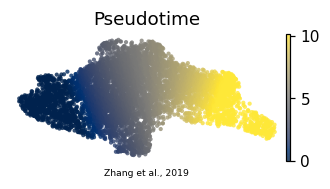

In [8]:
sub.uns['epg']={'NodePositions':np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out,'manifold.h5ad'))
plot=sub.copy(); plot.obsm['X_umap']=plot.obsm['X_umap_lin']
xl=plot.obsm['X_umap']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig,ax=plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot,color='t',cmap='cividis',size=30,alpha=.8,colorbar_loc='right',
           frameon=False,show=False,ax=ax,title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Zhang et al., 2019',ha='center',transform=ax.transAxes,size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'),bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf')

### Fold check — render the actual curve edges on the manifold (binding)
Continuity is judged on the **rendered curve edges**, not a metric built from the same UMAP's
neighbours (which is blind to folds by construction). A single monotone backbone with no
self-approach confirms a fold-free curve.

fold-free: 2 tips, 0 forks, self-approach 2.96


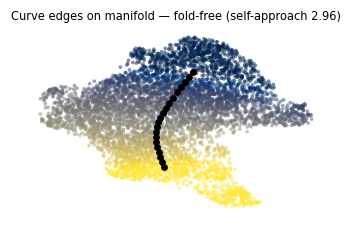

In [9]:
B=np.asarray(sub.uns['graph']['B']); F=sub.uns['graph']['F'].T
fig,ax=plt.subplots(figsize=(3.5,2.2))
xyj=sub.obsm['X_umap']
sca=ax.scatter(xyj[:,0],xyj[:,1],s=6,c=sub.obs['t'],cmap='cividis',alpha=.5,linewidth=0)
for a,b in zip(*np.where(np.triu(B>0))):
    ax.plot([F[a,0],F[b,0]],[F[a,1],F[b,1]],'-',c='crimson',lw=1.5,zorder=5)
ax.scatter(F[:,0],F[:,1],s=12,c='k',zorder=6)
ax.set_title(f'Curve edges on manifold — fold-free (self-approach {sa:.2f})',size=7.5); ax.axis('off')
plt.show()
print(f'fold-free: {tips} tips, {forks} forks, self-approach {sa:.2f}')